In [1]:
# 1. Get the code (replace with your team repo URL)
REPO = "https://github.com/Khalid-Fahad-AE/F21dl-DMML-PG20"
!git clone -q $REPO project
%cd project

/content/project


In [2]:
# 2. Get the ORIGINAL PlantVillage tomato images (~314 MB) and the PlantDoc tomato field photos (~150 MB)
!git clone -q --filter=blob:none --no-checkout --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/pv
!cd /content/pv && git sparse-checkout init --no-cone && echo '/raw/color/Tomato___*/' > .git/info/sparse-checkout && git checkout -q master
!git clone -q --filter=blob:none --no-checkout --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git /content/plantdoc
!cd /content/plantdoc && git sparse-checkout init --no-cone && printf '/train/Tomato*\n/test/Tomato*\n' > .git/info/sparse-checkout && git checkout -q master
!ln -sfn /content/pv/raw/color data/plantvillage_color && ln -sfn /content/plantdoc data/plantdoc
!ls data/plantvillage_color | head -3; find data/plantdoc/ -name '*.jpg' | wc -l

remote: Enumerating objects: 18146, done.
remote: Counting objects: 100% (18146/18146), done.
remote: Compressing objects: 100% (18146/18146), done.
remote: Total 18146 (delta 0), reused 18146 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18146/18146), 271.12 MiB | 32.34 MiB/s, done.
remote: Enumerating objects: 743, done.
remote: Counting objects: 100% (743/743), done.
remote: Compressing objects: 100% (743/743), done.
remote: Total 743 (delta 0), reused 743 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (743/743), 225.36 MiB | 43.19 MiB/s, done.
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___healthy
745


In [3]:
# 3. Dependencies (torch/torchvision are preinstalled on Colab)
!pip -q install -r requirements.txt
import torch; print(torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

2.14.1+cu130 Tesla T4


In [4]:
# 4. Check the shared split is intact: 18133 rows = train 12696 / val 2718 / test 2719
import pandas as pd; s = pd.read_csv("data/splits.csv"); print(len(s)); print(s.split.value_counts())

18133
split
train    12696
test      2719
val       2718
Name: count, dtype: int64


In [11]:
from google.colab import files
files.upload()   # pick the cnn.py you downloaded
!mv -f cnn.py src/cnn.py
!grep -n "deepcopy" src/cnn.py

Saving cnn.py to cnn.py
75:    lat = latency_ms(copy.deepcopy(model).to("cpu"), size, torch.device("cpu"))


## Workstream E: small CNN from scratch, augmentation ablation (none / geo / full)

In [12]:
!python src/cnn.py --aug all --size 128 --epochs 30 --workers 2

[CNN_scratch_none_128] found saved checkpoint, skipping training
[CNN_scratch_none_128] acc=0.9956 macroP=0.9948 macroR=0.9952 macroF1=0.9950
/content/project/src/evaluate.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  row = pd.concat([old, row], ignore_index=True)
[CNN_scratch_none_128@PlantDoc] acc=0.2386 macroP=0.2189 macroR=0.1749 macroF1=0.1425
[CNN_scratch_geo_128] epoch=1 train_loss=0.7918 train_acc=0.7416 val_loss=0.6788 val_acc=0.7609 val_macro_f1=0.7034 elapsed_s=32.3588
[CNN_scratch_geo_128] epoch=2 train_loss=0.4720 train_acc=0.8422 val_loss=0.8409 val_acc=0.7483 val_macro_f1=0.6555 elapsed_s=66.3514
[CNN_scratch_geo_128] epoch=3 train_loss=0.3679 train_acc=0.8765 val_loss=0.5017 val_acc=0.8337 val_macro_f1=0.7950 elapsed_

In [13]:
!python src/gradcam.py --model CNN_scratch_full_128 --size 128
!python src/gradcam.py --model CNN_scratch_none_128 --size 128

mask plausible for 98.2% of images
         cam_mass_on_leaf  leaf_area_share  leaf_focus_ratio
correct                                                     
False            0.563594         0.379123          1.511045
True             0.632967         0.393679          1.670270
mask plausible for 98.2% of images
         cam_mass_on_leaf  leaf_area_share  leaf_focus_ratio
correct                                                     
False            0.438542         0.347070          1.247683
True             0.566020         0.394655          1.476317


## Workstream F: transfer learning (frozen backbone, then partial unfreeze)

In [14]:
!python src/transfer.py --arch all --workers 2

[TL_mobilenet_v2_stage1] epoch=1 train_loss=0.9554 train_acc=0.7147 val_loss=0.5998 val_acc=0.8131 val_macro_f1=0.7041 elapsed_s=71.6110
[TL_mobilenet_v2_stage1] epoch=2 train_loss=0.5510 train_acc=0.8320 val_loss=0.4740 val_acc=0.8543 val_macro_f1=0.7915 elapsed_s=146.8137
[TL_mobilenet_v2_stage1] epoch=3 train_loss=0.4797 train_acc=0.8491 val_loss=0.4545 val_acc=0.8525 val_macro_f1=0.8006 elapsed_s=220.9411
[TL_mobilenet_v2_stage1] epoch=4 train_loss=0.4401 train_acc=0.8633 val_loss=0.4187 val_acc=0.8613 val_macro_f1=0.8103 elapsed_s=295.7892
[TL_mobilenet_v2_stage1] epoch=5 train_loss=0.4270 train_acc=0.8658 val_loss=0.4156 val_acc=0.8639 val_macro_f1=0.8144 elapsed_s=368.9670
/content/project/src/evaluate.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before th

In [15]:
!python src/gradcam.py --model TL_mobilenet_v2 --size 224

mask plausible for 98.0% of images
         cam_mass_on_leaf  leaf_area_share  leaf_focus_ratio
correct                                                     
False            0.476358         0.318331          1.482184
True             0.608979         0.392932          1.598301


## Results: every model in one table (the same evaluate.py as the classic models)

                        model        group    split    n  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  train_time_s  infer_ms_per_img   n_params                                                                                                                                           notes
                   GaussianNB    C classic     test 2719    0.6977           0.6595        0.7080    0.6717       0.7009        0.1623            0.0358        NaN                                                              raw features; best {"var_smoothing": 1e-06}; cv macroF1=0.6761; val macroF1=0.6780
           LogisticRegression    C classic     test 2719    0.8860           0.8656        0.8547    0.8594       0.8847        2.4802            0.0009        NaN                                                     pca features; best {"C": 0.01, "class_weight": null}; cv macroF1=0.8593; val macroF1=0.8604
                          KNN    C classic     test 2719    0.8474          

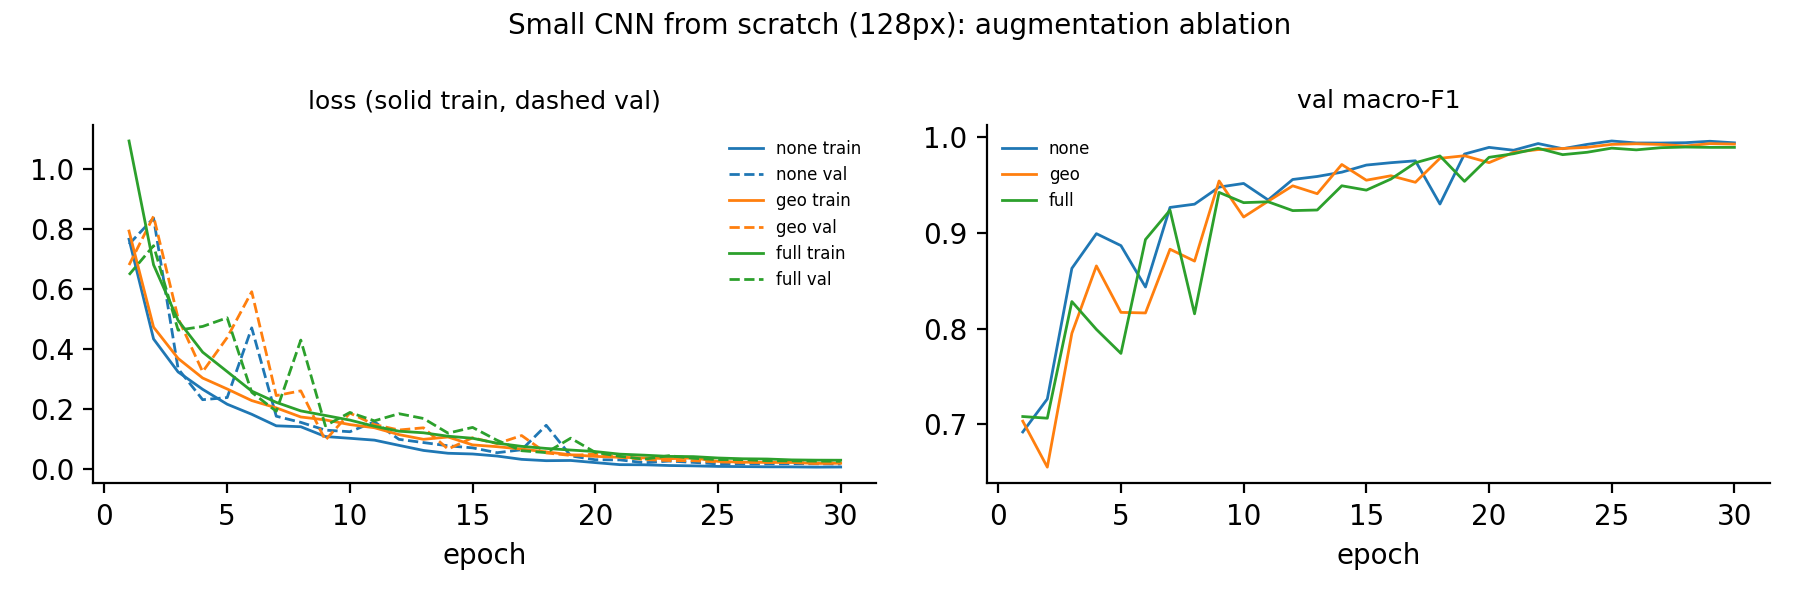

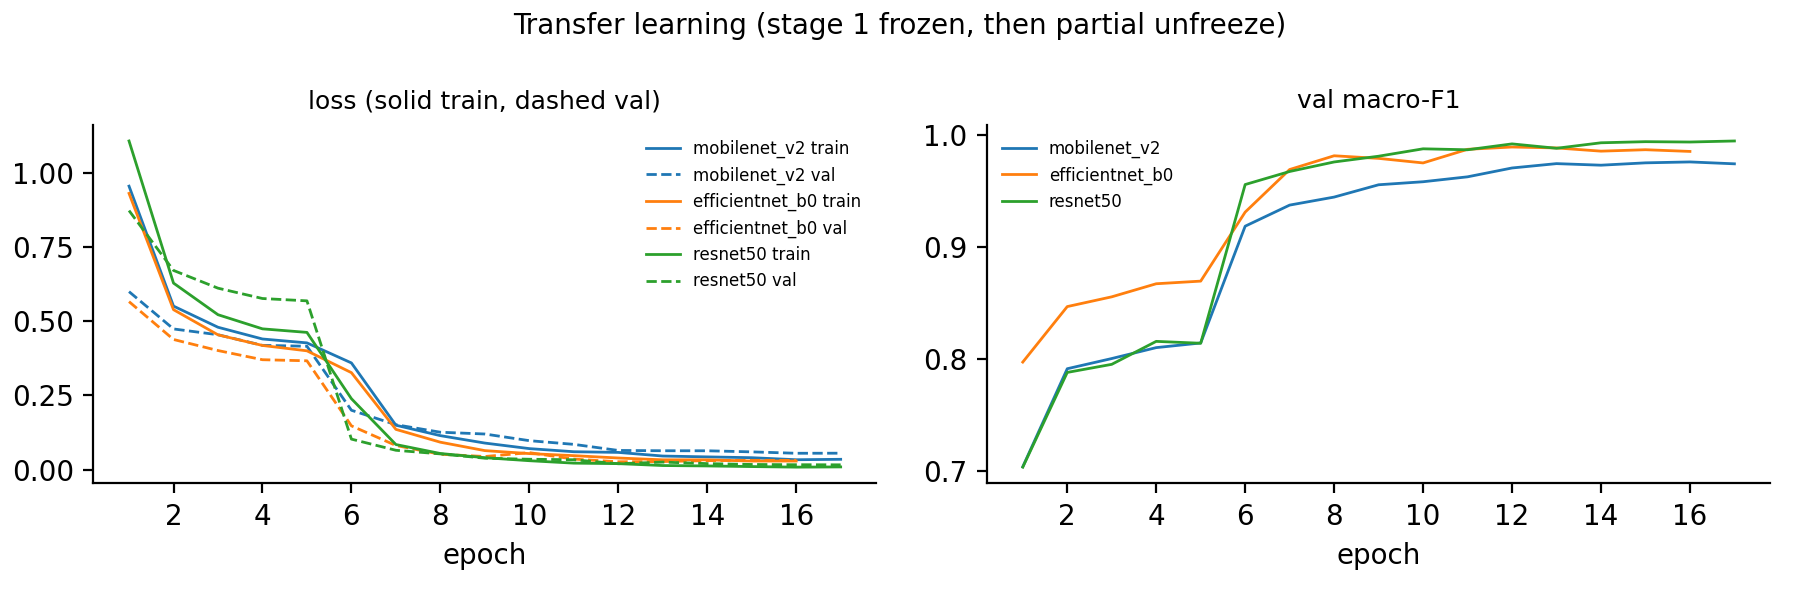

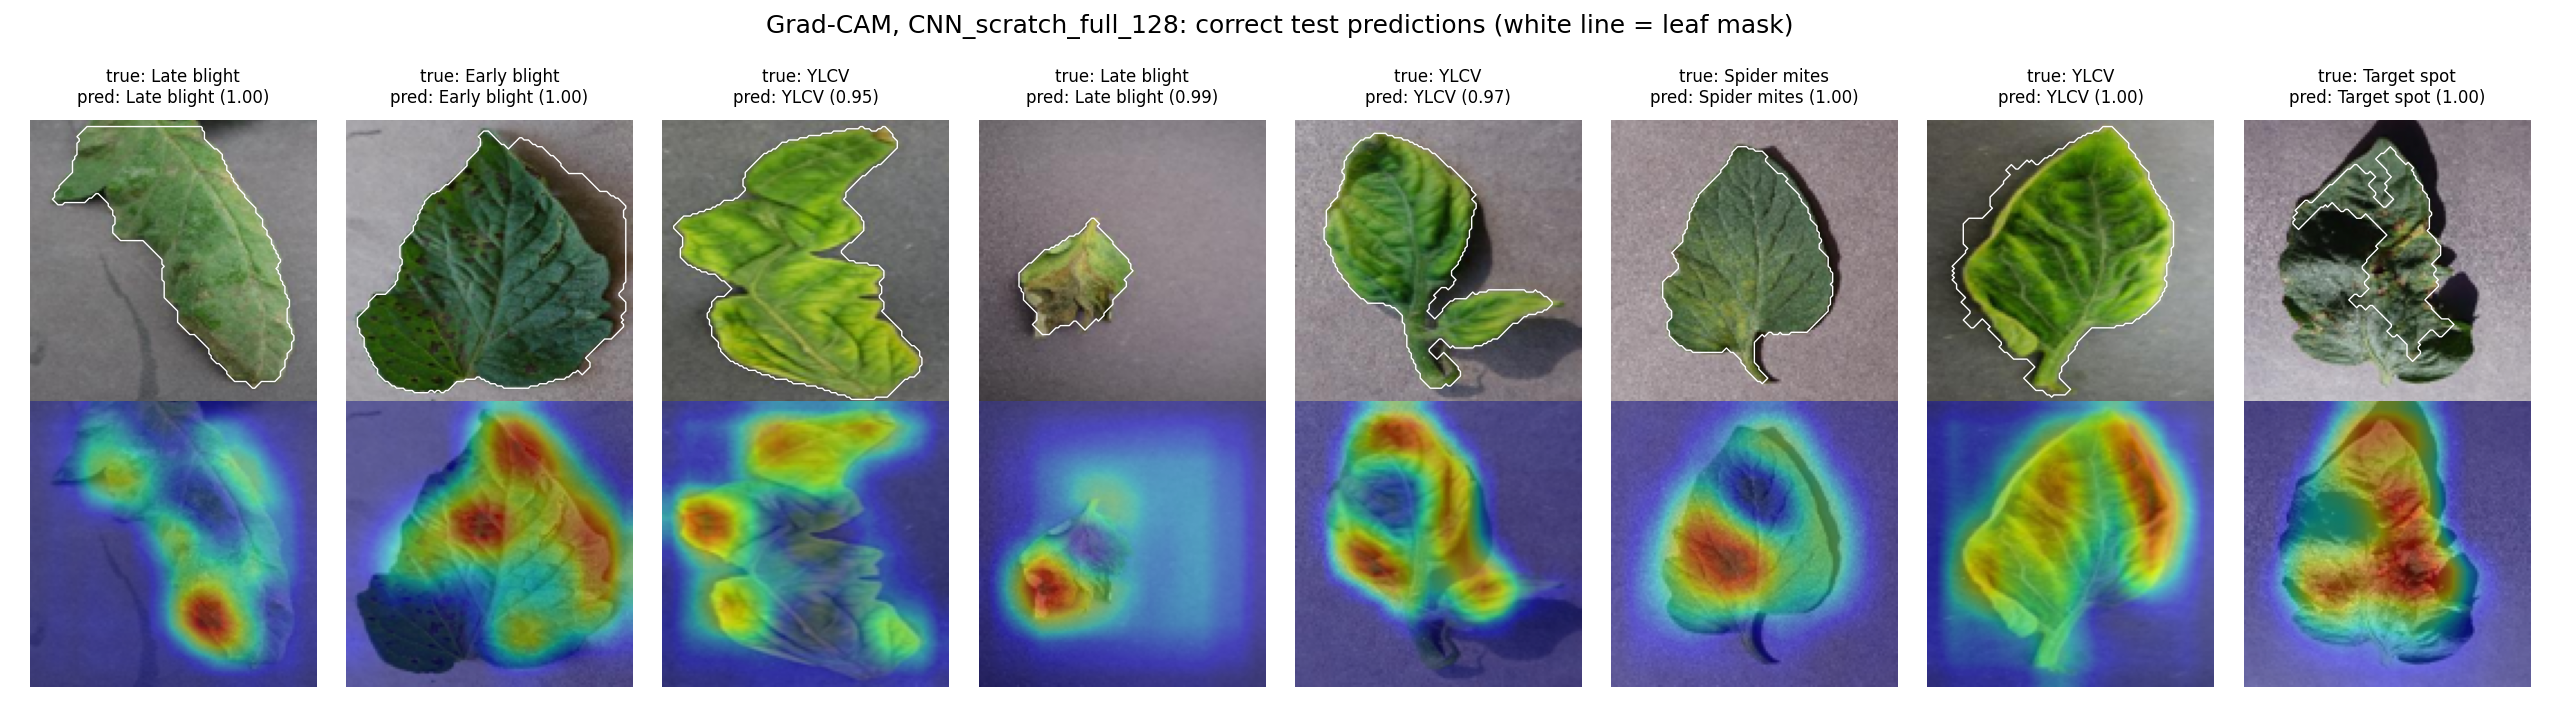

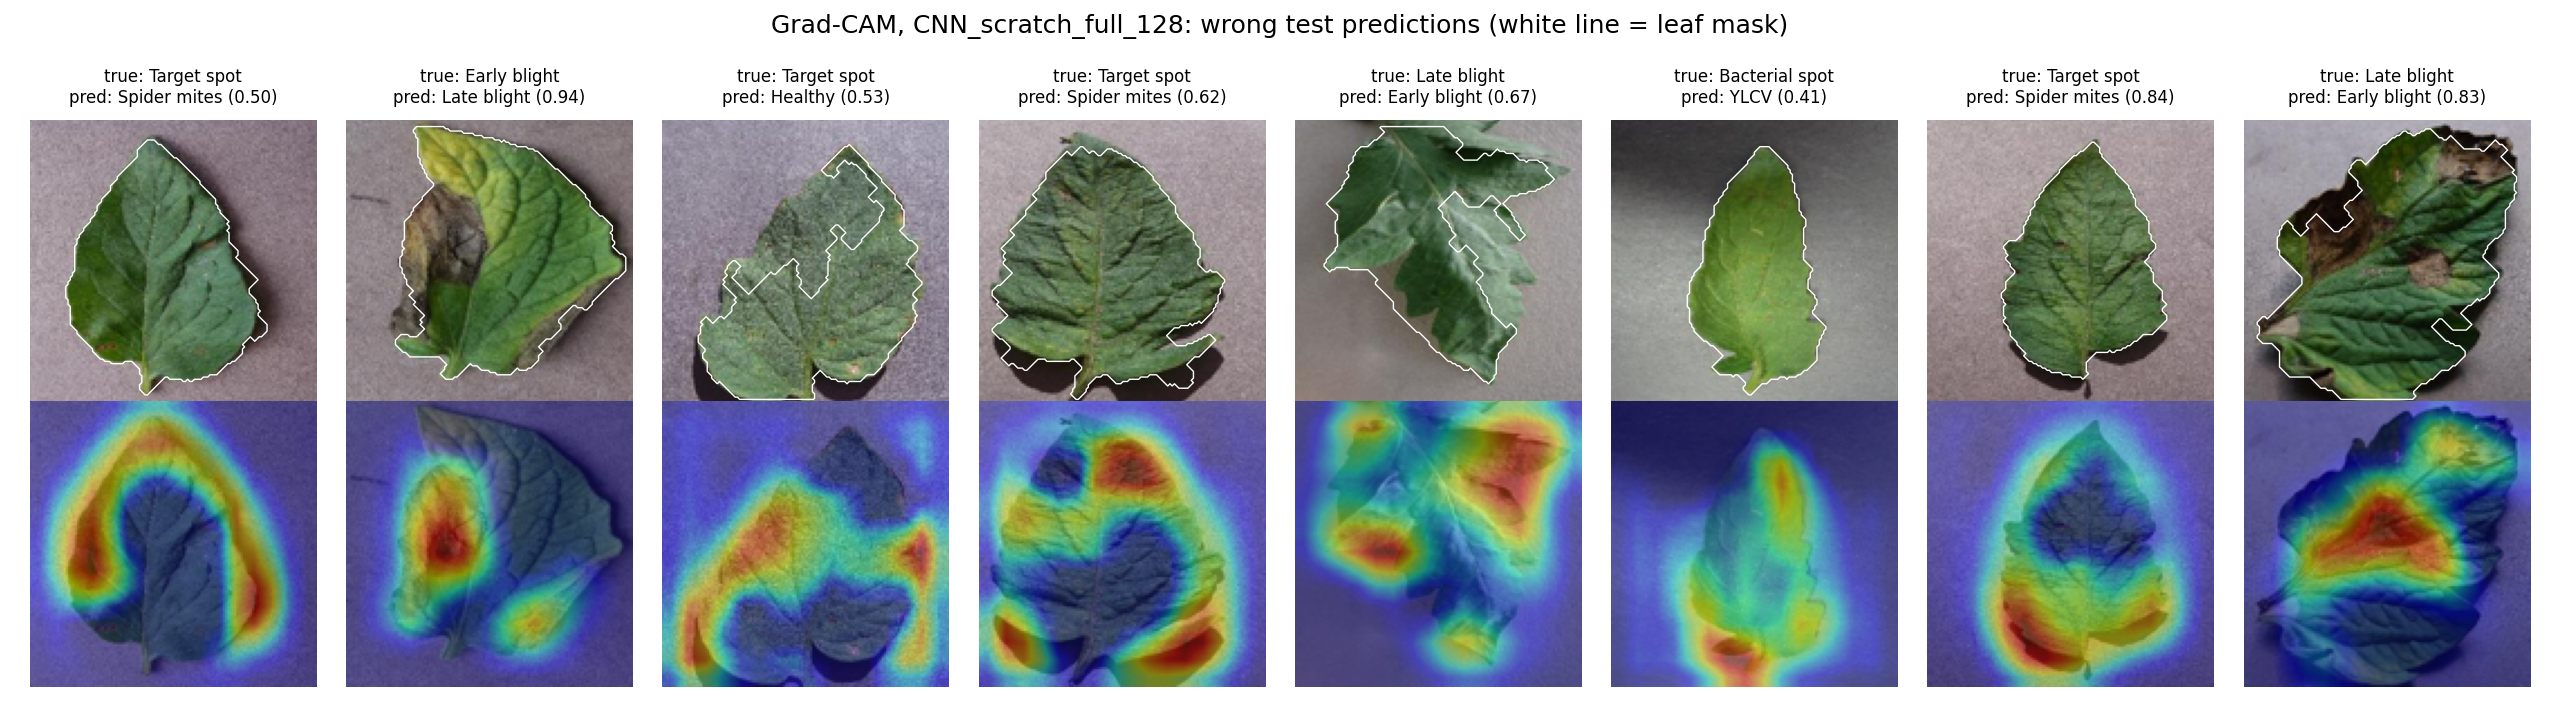

In [16]:
!python src/evaluate.py
from IPython.display import Image, display
for f in ["cnn_curves_128.png", "transfer_curves.png", "gradcam_CNN_scratch_full_128_correct.png",
          "gradcam_CNN_scratch_full_128_wrong.png"]:
    display(Image(f"results/figures/{f}", width=800))

In [17]:
# 5. Save results back to the repo (or download the zip)
!zip -qr results_EF.zip results/tables results/figures
from google.colab import files; files.download("results_EF.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>